# Binary Risk Classification - EfficientNet-B0
## Strict Matching + Side Cropping + EfficientNet-B0 Architecture

**Author:** Minu  
**Supervisor:** Dr. Prasan Yapa

---

## 🚀 Why EfficientNet-B0?

### **Advantages over ResNet50:**
1. ✅ **More efficient** - Fewer parameters (5.3M vs 25.6M)
2. ✅ **Better accuracy-per-parameter** - Compound scaling
3. ✅ **Faster training** - Reduced computational cost
4. ✅ **Less overfitting risk** - Smaller model for small datasets
5. ✅ **Mobile-friendly** - Could deploy in dental clinics

### **Architecture Comparison:**
| Model | Parameters | ImageNet Top-1 | Training Speed |
|-------|------------|----------------|----------------|
| ResNet50 | 25.6M | 76.1% | Baseline |
| **EfficientNet-B0** | **5.3M** | **77.1%** | **~1.5x faster** |

---

In [ ]:
# Check GPU
import torch
print(f"PyTorch: {torch.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")

PyTorch: 2.10.0+cu128
CUDA Available: True
GPU: Tesla T4
Memory: 15.64 GB


In [ ]:
# Mount Drive
try:
    from google.colab import drive
    drive.mount('/content/drive')
    print("✅ Drive mounted")
except:
    print("Not in Colab or already mounted")

Mounted at /content/drive
✅ Drive mounted


In [ ]:
# Imports
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, roc_curve,
    precision_recall_curve, average_precision_score
)
from sklearn.utils.class_weight import compute_class_weight
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import torchvision.transforms as transforms
from torchvision import models
from PIL import Image
import warnings
warnings.filterwarnings('ignore')

def set_seed(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)
print("✅ Imports complete")

✅ Imports complete


In [ ]:
# Configure paths
IMAGES_DIR = "/content/drive/MyDrive/FINAL_YEAR/DPT_1234new"  # Folder containing DPT images
EXCEL_PATH = "/content/drive/MyDrive/FINAL_YEAR/DPT_1234new/Risk_assessment.xlsx"
OUTPUT_DIR = "/content/drive/MyDrive/FINAL_YEAR/AblationClassificationResults/binary_results_efficientnet"

os.makedirs(OUTPUT_DIR, exist_ok=True)
CROPPED_DIR = os.path.join(OUTPUT_DIR, 'cropped_images')
os.makedirs(CROPPED_DIR, exist_ok=True)

print("📁 Paths configured:")
print(f"Images: {IMAGES_DIR}")
print(f"Excel: {EXCEL_PATH}")
print(f"Output: {OUTPUT_DIR}")

📁 Paths configured:
Images: /content/drive/MyDrive/FINAL_YEAR/DPT_1234new
Excel: /content/drive/MyDrive/FINAL_YEAR/DPT_1234new/Risk_assessment.xlsx
Output: /content/drive/MyDrive/FINAL_YEAR/AblationClassificationResults/binary_results_efficientnet


## 🔪 Image Cropping & Matching Functions

In [ ]:
def crop_image_by_side(image_path, side, output_dir):
    """Crop DPT at midline to isolate left or right side"""
    img = Image.open(image_path)
    width, height = img.size
    midline = width // 2

    if side == 'LS':
        cropped = img.crop((0, 0, midline, height))
    elif side == 'RS':
        cropped = img.crop((midline, 0, width, height))
    else:
        raise ValueError(f"Invalid side: {side}")

    base_name = os.path.splitext(os.path.basename(image_path))[0]
    output_filename = f"{base_name}_{side}.jpg"
    output_path = os.path.join(output_dir, output_filename)
    cropped.save(output_path, quality=95)

    return output_path

def normalize_dpt_number(dpt_str):
    """Conservative normalization"""
    return str(dpt_str).strip().replace(' ', '').replace('-', '').upper()

def strict_match_dpt(excel_dpt, image_mapping):
    """Strict matching: exact or unique normalized match only"""
    # Try exact match
    if excel_dpt in image_mapping:
        return image_mapping[excel_dpt], 'exact'

    # Try normalized match
    excel_normalized = normalize_dpt_number(excel_dpt)
    matches = []
    for img_base, img_path in image_mapping.items():
        if normalize_dpt_number(img_base) == excel_normalized:
            matches.append((img_base, img_path))

    if len(matches) == 1:
        return matches[0][1], 'normalized'
    elif len(matches) > 1:
        return None, 'ambiguous'
    else:
        return None, 'no_match'

print("✅ Functions defined")

✅ Functions defined


## 📊 Data Loading with Strict Matching

In [ ]:
print("="*60)
print("LOADING DATA (STRICT MATCHING + EfficientNet)")
print("="*60)

# Load Excel
df = pd.read_excel(EXCEL_PATH)
print(f"\nTotal Excel rows: {len(df)}")

df_filtered = df.copy()
df_filtered = df_filtered.dropna(subset=['DPT no'])
print(f"After dropna: {len(df_filtered)} rows")

# Get images
available_images = [img for img in os.listdir(IMAGES_DIR)
                   if img.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp'))]
print(f"Available images: {len(available_images)}")

# Create mapping
image_mapping = {}
for img_name in available_images:
    base_name = os.path.splitext(img_name)[0]
    image_mapping[base_name] = os.path.join(IMAGES_DIR, img_name)

# Process with strict matching
matched_data = []
match_stats = {'exact': 0, 'normalized': 0, 'ambiguous': 0, 'no_match': 0, 'error': 0}
used_images = {}

print("\n🔪 Processing...\n")

for idx, row in df_filtered.iterrows():
    if idx % 100 == 0:
        print(f"Processing {idx}/{len(df_filtered)}...")

    dpt_no = str(row['DPT no']).strip()
    side = row['Side']
    risk_level = row['Level of Risk of nerve damage']
    binary_risk = 'Low' if risk_level == 'Low' else 'High-Risk'

    img_path, match_type = strict_match_dpt(dpt_no, image_mapping)

    if img_path is not None:
        try:
            cropped_path = crop_image_by_side(img_path, side, CROPPED_DIR)

            original_img = os.path.basename(img_path)
            if original_img not in used_images:
                used_images[original_img] = []
            used_images[original_img].append((dpt_no, side))

            matched_data.append({
                'image_path': cropped_path,
                'risk_level': binary_risk,
                'original_risk': risk_level,
                'dpt_no': dpt_no,
                'side': side,
                'original_image': original_img,
                'match_type': match_type
            })
            match_stats[match_type] += 1

        except Exception as e:
            print(f"⚠️ Error: {dpt_no} {side}: {e}")
            match_stats['error'] += 1
    else:
        match_stats[match_type] += 1

df_matched = pd.DataFrame(matched_data)

print("\n" + "="*60)
print("📊 MATCHING STATISTICS")
print("="*60)
print(f"\nSuccessfully matched: {len(df_matched)}")
print(f"Unique images used: {len(used_images)}")
print(f"\nMatch breakdown:")
for match_type, count in match_stats.items():
    print(f"  {match_type}: {count}")

print("\n📊 Risk Distribution:")
print(df_matched['risk_level'].value_counts())

print("\nBy Side:")
print(df_matched.groupby(['side', 'risk_level']).size().unstack(fill_value=0))

# Duplicate check
dup_check = df_matched['image_path'].value_counts()
duplicates = dup_check[dup_check > 1]
if len(duplicates) > 0:
    print(f"\n⚠️ WARNING: {len(duplicates)} duplicates!")
else:
    print("\n✅ NO DUPLICATES!")

# Save
csv_path = os.path.join(OUTPUT_DIR, 'matched_data_efficientnet.csv')
df_matched.to_csv(csv_path, index=False)
print(f"\nData saved: {csv_path}")

LOADING DATA (STRICT MATCHING + EfficientNet)

Total Excel rows: 1093
After dropna: 1093 rows
Available images: 484

🔪 Processing...

Processing 0/1093...
Processing 100/1093...
Processing 200/1093...
Processing 300/1093...
Processing 400/1093...
Processing 500/1093...
Processing 600/1093...
Processing 700/1093...
Processing 800/1093...
Processing 900/1093...
Processing 1000/1093...

📊 MATCHING STATISTICS

Successfully matched: 713
Unique images used: 375

Match breakdown:
  exact: 711
  normalized: 2
  ambiguous: 0
  no_match: 380
  error: 0

📊 Risk Distribution:
risk_level
Low          590
High-Risk    123
Name: count, dtype: int64

By Side:
risk_level  High-Risk  Low
side                      
LS                 57  296
RS                 66  294

⚠️ WARNING: 5 duplicates!

Data saved: /content/drive/MyDrive/FINAL_YEAR/AblationClassificationResults/binary_results_efficientnet/matched_data_efficientnet.csv


## 🧠 Dataset & EfficientNet-B0 Model

In [ ]:
class DPTRiskDataset(Dataset):
    """Custom Dataset for DPT Risk Classification"""
    def __init__(self, image_paths, labels, transform=None):
        self.image_paths = image_paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        image = Image.open(img_path).convert('RGB')
        label = self.labels[idx]

        if self.transform:
            image = self.transform(image)

        return image, label, img_path

print("✅ Dataset class defined")

✅ Dataset class defined


In [ ]:
class EfficientNetB0Classifier(nn.Module):
    """
    EfficientNet-B0 for Binary Risk Classification

    Architecture:
    - Backbone: EfficientNet-B0 (pretrained on ImageNet)
    - Input: 224x224 RGB images
    - Output: 2 classes (Low, High-Risk)

    Parameters: ~5.3M (vs ResNet50's 25.6M)
    """
    def __init__(self, num_classes=2, pretrained=True, dropout=0.5):
        super(EfficientNetB0Classifier, self).__init__()

        # Load pretrained EfficientNet-B0
        self.efficientnet = models.efficientnet_b0(pretrained=pretrained)

        # Get number of features from last layer
        num_features = self.efficientnet.classifier[1].in_features

        # Replace classifier head
        self.efficientnet.classifier = nn.Sequential(
            nn.Dropout(p=dropout, inplace=True),
            nn.Linear(num_features, num_classes)
        )

    def forward(self, x):
        return self.efficientnet(x)

# Test model initialization
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
test_model = EfficientNetB0Classifier(num_classes=2, pretrained=True, dropout=0.5)
test_model = test_model.to(device)

# Count parameters
total_params = sum(p.numel() for p in test_model.parameters())
trainable_params = sum(p.numel() for p in test_model.parameters() if p.requires_grad)

print("✅ EfficientNet-B0 Model defined")
print(f"\n📊 Model Statistics:")
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Model size: ~{total_params * 4 / 1e6:.1f} MB (FP32)")

del test_model  # Clean up

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 126MB/s] 


✅ EfficientNet-B0 Model defined

📊 Model Statistics:
Total parameters: 4,010,110
Trainable parameters: 4,010,110
Model size: ~16.0 MB (FP32)


## 🎯 Data Preparation & Augmentation

**Note:** EfficientNet uses same 224x224 input as ResNet

In [ ]:
# Initialize
class_to_idx = {'Low': 0, 'High-Risk': 1}
idx_to_class = {v: k for k, v in class_to_idx.items()}

# Prepare data
labels = df_matched['risk_level'].map(class_to_idx).values
image_paths = df_matched['image_path'].values

# Split with stratification
X_temp, X_test, y_temp, y_test = train_test_split(
    image_paths, labels, test_size=0.2, stratify=labels, random_state=42
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.125, stratify=y_temp, random_state=42
)

print("📊 Dataset Splits:")
print(f"Train: {len(X_train)}, Val: {len(X_val)}, Test: {len(X_test)}")

for name, split_labels in [('Train', y_train), ('Val', y_val), ('Test', y_test)]:
    unique, counts = np.unique(split_labels, return_counts=True)
    print(f"\n{name}:")
    for cls_idx, count in zip(unique, counts):
        print(f"  {idx_to_class[cls_idx]}: {count}")

📊 Dataset Splits:
Train: 498, Val: 72, Test: 143

Train:
  Low: 412
  High-Risk: 86

Val:
  Low: 60
  High-Risk: 12

Test:
  Low: 118
  High-Risk: 25


In [ ]:
# Data augmentation
# EfficientNet uses same ImageNet normalization as ResNet
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),  # Slightly more aggressive
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),  # Small translations
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Create datasets
train_dataset = DPTRiskDataset(X_train, y_train, train_transform)
val_dataset = DPTRiskDataset(X_val, y_val, val_transform)
test_dataset = DPTRiskDataset(X_test, y_test, val_transform)

# Weighted sampler for class imbalance
class_counts = np.bincount(y_train)
class_weights_sample = 1. / class_counts
sample_weights = class_weights_sample[y_train]
sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

# Data loaders
BATCH_SIZE = 32  # Can use larger batch for EfficientNet (smaller model)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, sampler=sampler, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"\n✅ Data loaders ready (batch size: {BATCH_SIZE})")


✅ Data loaders ready (batch size: 32)


## 🔬 Ablation Study — Isolate-One-Only

**Components under study:**
| Experiment | Pretraining | Weighted Loss | Augmentation |
|---|---|---|---|
| E0 - No Components | ❌ | ❌ | ❌ |
| E1 - Only Pretraining | ✅ | ❌ | ❌ |
| E2 - Only Weighted Loss | ❌ | ✅ | ❌ |
| E3 - Only Augmentation | ❌ | ❌ | ✅ |

All other settings (architecture, optimizer, scheduler, epochs, splits, sampler) are unchanged.


In [ ]:
# ── Ablation Experiment Configurations ──────────────────────────────────────
ABLATION_EXPERIMENTS = [
    {
        'name': 'E0_No_Components',
        'use_pretrained': False,
        'use_weighted_loss': False,
        'use_augmentation': False,
    },
    {
        'name': 'E1_Only_Pretraining',
        'use_pretrained': True,
        'use_weighted_loss': False,
        'use_augmentation': False,
    },
    {
        'name': 'E2_Only_Weighted_Loss',
        'use_pretrained': False,
        'use_weighted_loss': True,
        'use_augmentation': False,
    },
    {
        'name': 'E3_Only_Augmentation',
        'use_pretrained': False,
        'use_weighted_loss': False,
        'use_augmentation': True,
    },
]

ABLATION_OUTPUT_DIR = os.path.join(OUTPUT_DIR, 'isolation_ablation_results')
os.makedirs(ABLATION_OUTPUT_DIR, exist_ok=True)

print("✅ Ablation configurations defined")
print(f"Output directory: {ABLATION_OUTPUT_DIR}")


✅ Ablation configurations defined
Output directory: /content/drive/MyDrive/FINAL_YEAR/AblationClassificationResults/binary_results_efficientnet/isolation_ablation_results


In [ ]:
# ── Helper: build transforms for a given config ──────────────────────────────
def build_transforms(use_augmentation):
    """Return train/val transforms. Val transform is always identical."""
    val_transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])

    if use_augmentation:
        train_transform = transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomRotation(degrees=15),
            transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1),
            transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        ])
    else:
        # No augmentation — only resize and normalize (same as val)
        train_transform = val_transform

    return train_transform, val_transform


# ── Helper: build data loaders for a given config ────────────────────────────
def build_loaders(use_augmentation):
    train_transform, val_transform = build_transforms(use_augmentation)

    train_dataset = DPTRiskDataset(X_train, y_train, train_transform)
    val_dataset   = DPTRiskDataset(X_val,   y_val,   val_transform)
    test_dataset  = DPTRiskDataset(X_test,  y_test,  val_transform)

    # WeightedRandomSampler stays active in all experiments
    class_counts_local = np.bincount(y_train)
    class_weights_sample_local = 1. / class_counts_local
    sample_weights_local = class_weights_sample_local[y_train]
    sampler_local = WeightedRandomSampler(
        weights=sample_weights_local,
        num_samples=len(sample_weights_local),
        replacement=True
    )

    BATCH_SIZE = 32
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, sampler=sampler_local, num_workers=2)
    val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
    test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

    return train_loader, val_loader, test_loader


# ── Helper: build model for a given config ───────────────────────────────────
def build_model(use_pretrained):
    model = EfficientNetB0Classifier(num_classes=2, pretrained=use_pretrained, dropout=0.5)
    return model.to(device)


# ── Helper: build criterion for a given config ───────────────────────────────
def build_criterion(use_weighted_loss):
    class_weights_np = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
    class_weights_tensor = torch.FloatTensor(class_weights_np).to(device)

    if use_weighted_loss:
        return nn.CrossEntropyLoss(weight=class_weights_tensor)
    else:
        return nn.CrossEntropyLoss()  # Unweighted


print("✅ Helper functions defined")


✅ Helper functions defined


In [ ]:
# ── Training function (identical logic to original notebook) ─────────────────
def run_training(model, criterion, train_loader, val_loader, exp_name, output_dir):
    """Run one full training loop. Returns (history, best_val_acc, best_model_path)."""
    set_seed(42)

    optimizer = optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=0.5, patience=5
    )

    EPOCHS = 25
    history = {
        'train_loss': [], 'train_acc': [],
        'val_loss':   [], 'val_acc':   [],
        'learning_rates': []
    }
    best_val_acc = 0.0
    best_model_path = os.path.join(output_dir, f'{exp_name}_best.pth')

    print(f"\n{'='*60}")
    print(f"🚀 TRAINING: {exp_name}")
    print(f"{'='*60}")
    print(f"Epochs: {EPOCHS} | Batch size: 32 | LR: 0.001 | Device: {device}\n")

    for epoch in range(EPOCHS):
        # ── Training phase ──
        model.train()
        train_loss, train_correct, train_total = 0.0, 0, 0

        for images, labels, _ in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            train_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            train_total += labels.size(0)
            train_correct += (predicted == labels).sum().item()

        train_loss /= train_total
        train_acc   = 100.0 * train_correct / train_total

        # ── Validation phase ──
        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0

        with torch.no_grad():
            for images, labels, _ in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * images.size(0)
                _, predicted = torch.max(outputs, 1)
                val_total += labels.size(0)
                val_correct += (predicted == labels).sum().item()

        val_loss /= val_total
        val_acc   = 100.0 * val_correct / val_total

        scheduler.step(val_loss)
        current_lr = optimizer.param_groups[0]['lr']

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        history['learning_rates'].append(current_lr)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save({
                'epoch': epoch,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'val_acc': val_acc,
                'val_loss': val_loss,
                'class_to_idx': class_to_idx,
                'history': history
            }, best_model_path)

        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(f"Epoch [{epoch+1:3d}/{EPOCHS}] | "
                  f"Train: Loss={train_loss:.4f} Acc={train_acc:6.2f}% | "
                  f"Val: Loss={val_loss:.4f} Acc={val_acc:6.2f}% | "
                  f"LR={current_lr:.6f}")

    print(f"\n✅ Done. Best Val Acc: {best_val_acc:.2f}%")
    return history, best_val_acc, best_model_path


print("✅ Training function defined")


✅ Training function defined


In [ ]:
# ── Evaluation function (identical logic to original notebook) ───────────────
from sklearn.metrics import precision_recall_fscore_support

def run_evaluation(model, best_model_path, test_loader, exp_name, output_dir):
    """Load best checkpoint and evaluate on test set. Returns metrics dict."""
    checkpoint = torch.load(best_model_path)
    model.load_state_dict(checkpoint['model_state_dict'])
    model.eval()

    all_preds, all_labels, all_probs = [], [], []

    with torch.no_grad():
        for images, labels, _ in test_loader:
            images = images.to(device)
            outputs = model(images)
            probs = torch.softmax(outputs, dim=1)
            _, predicted = torch.max(outputs, 1)

            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.numpy())
            all_probs.extend(probs.cpu().numpy())

    all_preds  = np.array(all_preds)
    all_labels = np.array(all_labels)
    all_probs  = np.array(all_probs)

    test_acc = 100.0 * (all_preds == all_labels).sum() / len(all_labels)
    roc_auc  = roc_auc_score(all_labels, all_probs[:, 1])
    pr_auc   = average_precision_score(all_labels, all_probs[:, 1])

    precision_per_class, recall_per_class, f1_per_class, _ = precision_recall_fscore_support(
        all_labels, all_preds, average=None
    )

    # Classification report
    report = classification_report(
        all_labels, all_preds,
        target_names=list(class_to_idx.keys()),
        digits=4
    )
    with open(os.path.join(output_dir, f'{exp_name}_classification_report.txt'), 'w') as f:
        f.write(report)

    # Confusion matrix plot
    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=list(class_to_idx.keys()),
                yticklabels=list(class_to_idx.keys()),
                annot_kws={'size': 13, 'weight': 'bold'})
    plt.title(f'Confusion Matrix — {exp_name}', fontweight='bold', fontsize=13)
    plt.ylabel('True Label'); plt.xlabel('Predicted Label')
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, f'{exp_name}_confusion_matrix.png'), dpi=300, bbox_inches='tight')
    plt.show()

    metrics = {
        'experiment':          exp_name,
        'test_acc':            round(test_acc, 2),
        'roc_auc':             round(roc_auc, 4),
        'pr_auc':              round(pr_auc, 4),
        'f1_low':              round(f1_per_class[0], 4),
        'f1_high_risk':        round(f1_per_class[1], 4),
        'recall_high_risk':    round(recall_per_class[1], 4),
        'precision_high_risk': round(precision_per_class[1], 4),
    }

    print(f"\n📊 {exp_name} Results:")
    print(f"   Test Acc:            {test_acc:.2f}%")
    print(f"   ROC-AUC:             {roc_auc:.4f}")
    print(f"   PR-AUC:              {pr_auc:.4f}")
    print(f"   F1 (Low):            {f1_per_class[0]:.4f}")
    print(f"   F1 (High-Risk):      {f1_per_class[1]:.4f}")
    print(f"   Recall (High-Risk):  {recall_per_class[1]:.4f}")

    return metrics


print("✅ Evaluation function defined")


✅ Evaluation function defined



############################################################
  EXPERIMENT: E0_No_Components
  Pretrained:     False
  Weighted Loss:  False
  Augmentation:   False
############################################################

🚀 TRAINING: E0_No_Components
Epochs: 25 | Batch size: 32 | LR: 0.001 | Device: cuda

Epoch [  1/25] | Train: Loss=0.5928 Acc= 73.49% | Val: Loss=0.6307 Acc= 83.33% | LR=0.001000
Epoch [  5/25] | Train: Loss=0.2151 Acc= 93.78% | Val: Loss=0.2924 Acc= 91.67% | LR=0.001000
Epoch [ 10/25] | Train: Loss=0.1031 Acc= 96.79% | Val: Loss=0.8301 Acc= 75.00% | LR=0.001000
Epoch [ 15/25] | Train: Loss=0.0247 Acc= 99.80% | Val: Loss=0.4990 Acc= 91.67% | LR=0.000500
Epoch [ 20/25] | Train: Loss=0.0210 Acc= 99.40% | Val: Loss=0.3914 Acc= 91.67% | LR=0.000250
Epoch [ 25/25] | Train: Loss=0.0387 Acc= 99.40% | Val: Loss=0.3834 Acc= 93.06% | LR=0.000125

✅ Done. Best Val Acc: 94.44%


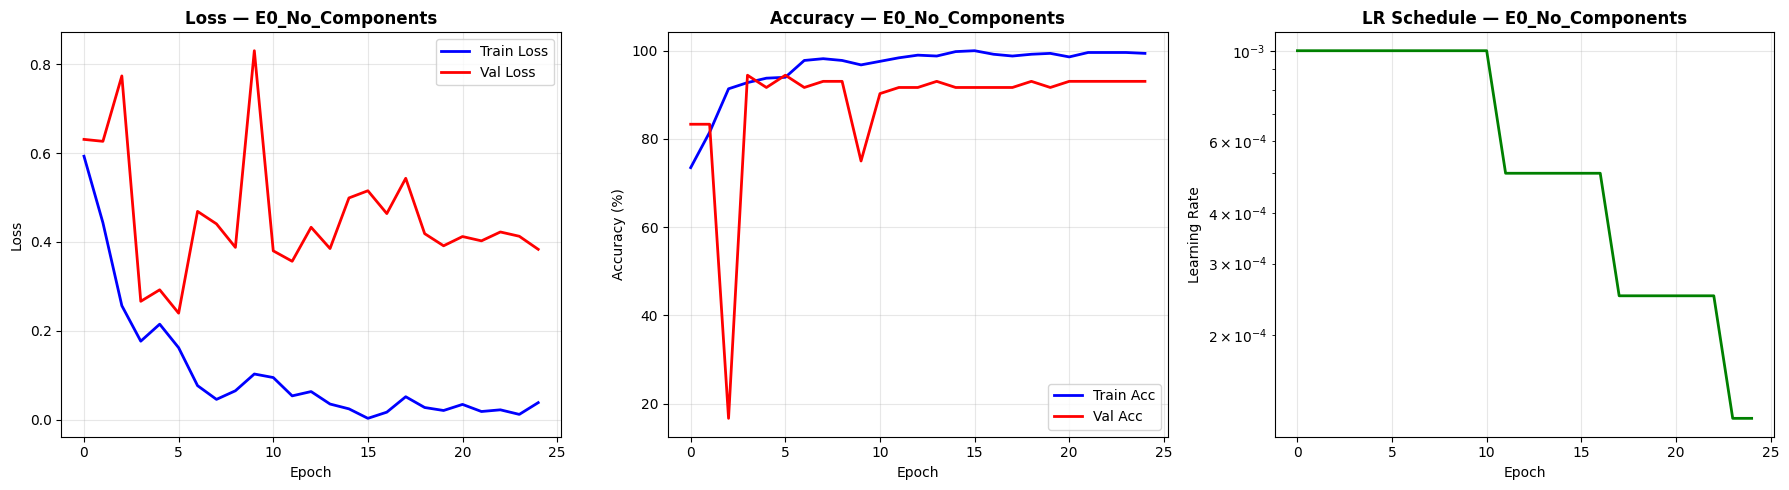

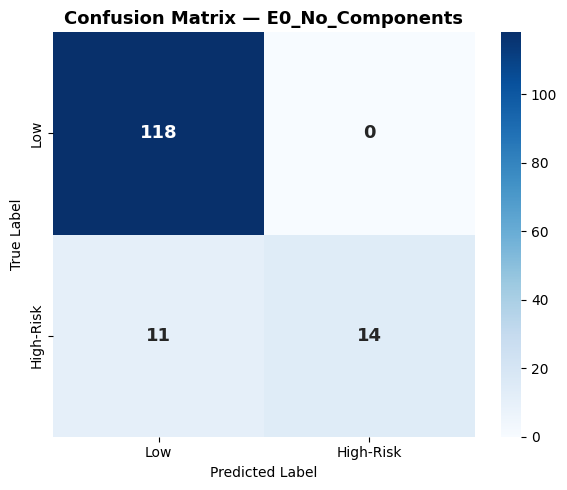


📊 E0_No_Components Results:
   Test Acc:            92.31%
   ROC-AUC:             0.8414
   PR-AUC:              0.7573
   F1 (Low):            0.9555
   F1 (High-Risk):      0.7179
   Recall (High-Risk):  0.5600

############################################################
  EXPERIMENT: E1_Only_Pretraining
  Pretrained:     True
  Weighted Loss:  False
  Augmentation:   False
############################################################

🚀 TRAINING: E1_Only_Pretraining
Epochs: 25 | Batch size: 32 | LR: 0.001 | Device: cuda

Epoch [  1/25] | Train: Loss=0.4419 Acc= 79.32% | Val: Loss=0.4559 Acc= 76.39% | LR=0.001000
Epoch [  5/25] | Train: Loss=0.0947 Acc= 96.79% | Val: Loss=0.3164 Acc= 90.28% | LR=0.001000
Epoch [ 10/25] | Train: Loss=0.0745 Acc= 96.99% | Val: Loss=0.6453 Acc= 90.28% | LR=0.001000
Epoch [ 15/25] | Train: Loss=0.0320 Acc= 99.00% | Val: Loss=0.3756 Acc= 93.06% | LR=0.000500
Epoch [ 20/25] | Train: Loss=0.0062 Acc= 99.80% | Val: Loss=0.5245 Acc= 94.44% | LR=0.000250
Epo

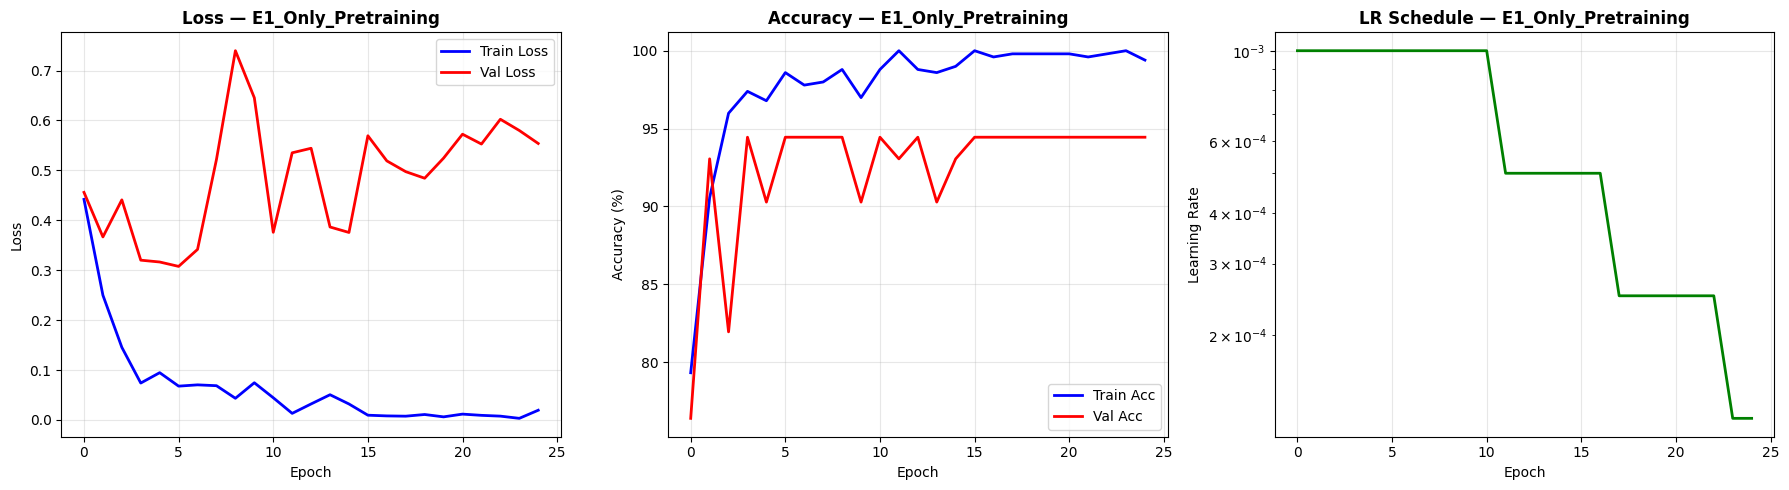

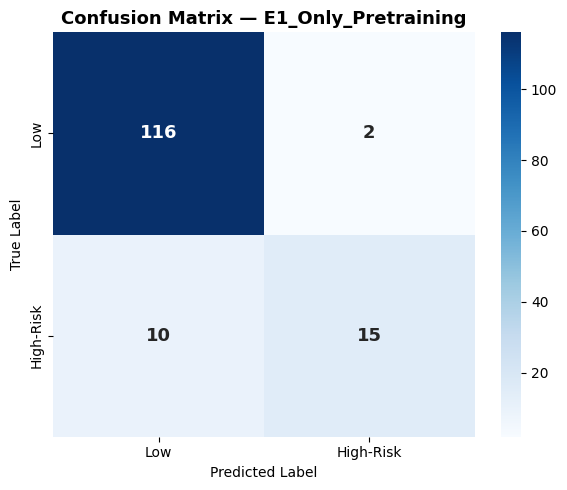


📊 E1_Only_Pretraining Results:
   Test Acc:            91.61%
   ROC-AUC:             0.7437
   PR-AUC:              0.6782
   F1 (Low):            0.9508
   F1 (High-Risk):      0.7143
   Recall (High-Risk):  0.6000

############################################################
  EXPERIMENT: E2_Only_Weighted_Loss
  Pretrained:     False
  Weighted Loss:  True
  Augmentation:   False
############################################################

🚀 TRAINING: E2_Only_Weighted_Loss
Epochs: 25 | Batch size: 32 | LR: 0.001 | Device: cuda

Epoch [  1/25] | Train: Loss=0.5000 Acc= 55.42% | Val: Loss=0.8211 Acc= 16.67% | LR=0.001000
Epoch [  5/25] | Train: Loss=0.1986 Acc= 85.74% | Val: Loss=0.6271 Acc= 51.39% | LR=0.001000
Epoch [ 10/25] | Train: Loss=0.0695 Acc= 95.18% | Val: Loss=0.8770 Acc= 84.72% | LR=0.001000
Epoch [ 15/25] | Train: Loss=0.0373 Acc= 97.59% | Val: Loss=0.7502 Acc= 91.67% | LR=0.000500
Epoch [ 20/25] | Train: Loss=0.0137 Acc= 99.40% | Val: Loss=0.7778 Acc= 91.67% | LR=0.000

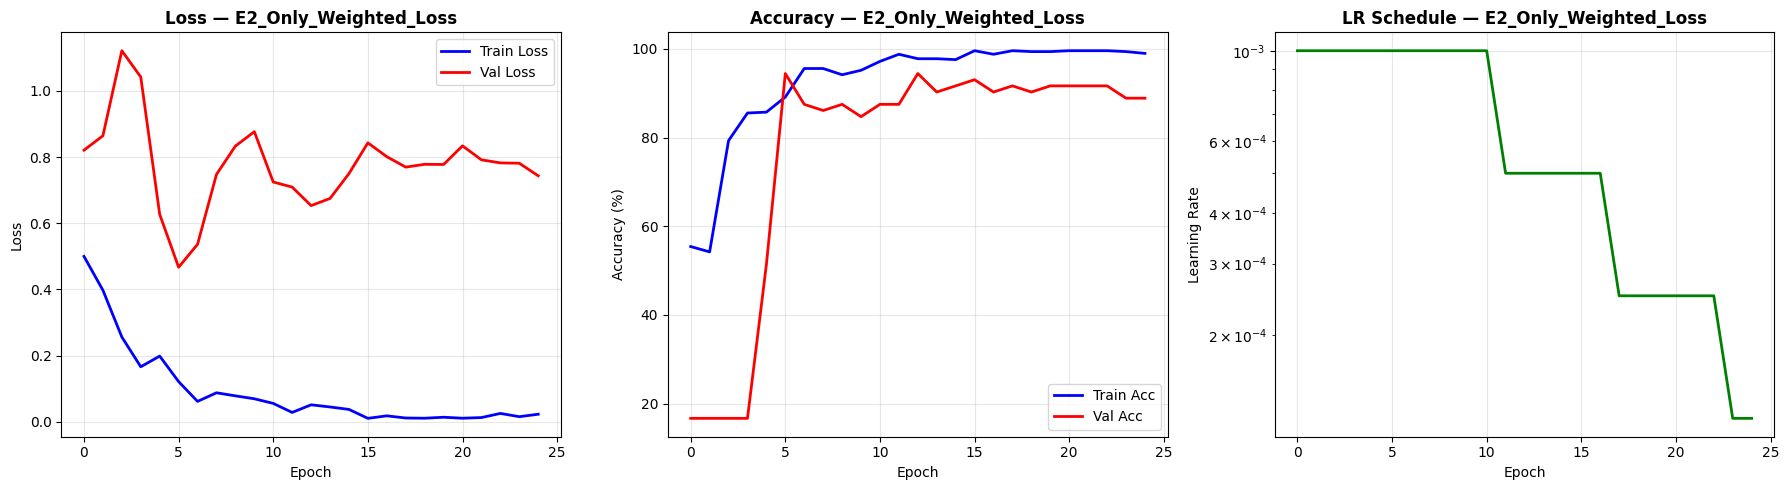

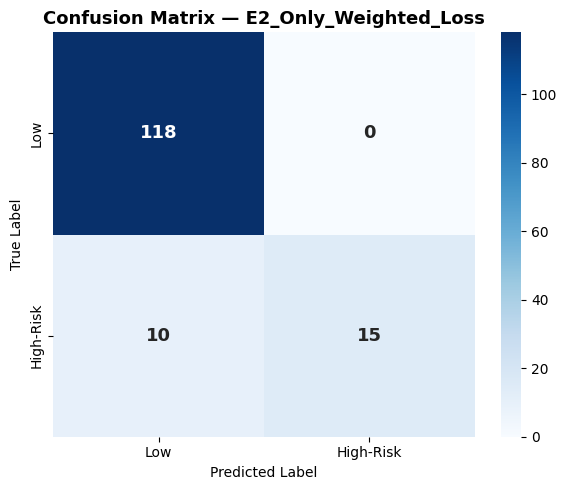


📊 E2_Only_Weighted_Loss Results:
   Test Acc:            93.01%
   ROC-AUC:             0.7766
   PR-AUC:              0.7376
   F1 (Low):            0.9593
   F1 (High-Risk):      0.7500
   Recall (High-Risk):  0.6000

############################################################
  EXPERIMENT: E3_Only_Augmentation
  Pretrained:     False
  Weighted Loss:  False
  Augmentation:   True
############################################################

🚀 TRAINING: E3_Only_Augmentation
Epochs: 25 | Batch size: 32 | LR: 0.001 | Device: cuda

Epoch [  1/25] | Train: Loss=0.7771 Acc= 49.80% | Val: Loss=0.6122 Acc= 83.33% | LR=0.001000
Epoch [  5/25] | Train: Loss=0.5557 Acc= 69.08% | Val: Loss=1.1044 Acc= 33.33% | LR=0.001000
Epoch [ 10/25] | Train: Loss=0.5361 Acc= 71.29% | Val: Loss=0.5321 Acc= 88.89% | LR=0.001000
Epoch [ 15/25] | Train: Loss=0.5466 Acc= 71.29% | Val: Loss=0.4787 Acc= 94.44% | LR=0.000500
Epoch [ 20/25] | Train: Loss=0.4722 Acc= 77.31% | Val: Loss=0.3270 Acc= 94.44% | LR=0.000

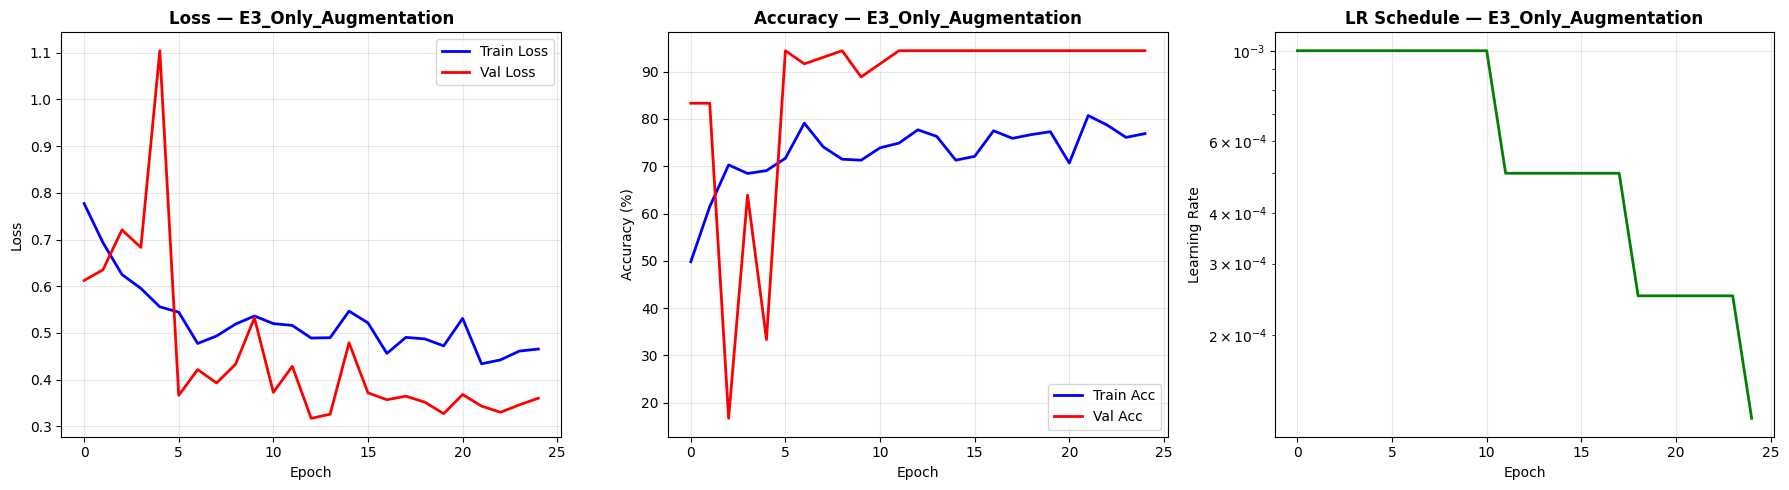

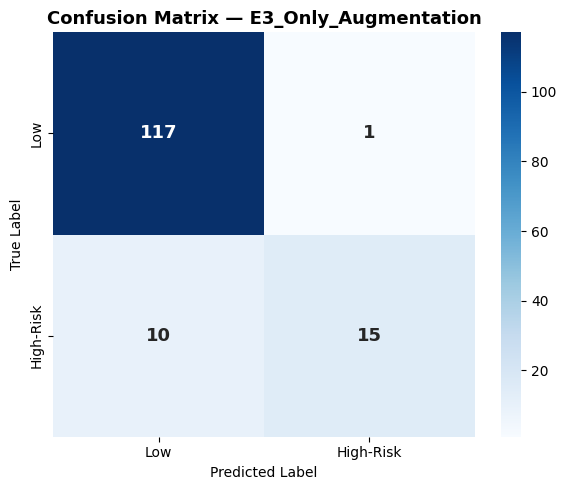


📊 E3_Only_Augmentation Results:
   Test Acc:            92.31%
   ROC-AUC:             0.8597
   PR-AUC:              0.7564
   F1 (Low):            0.9551
   F1 (High-Risk):      0.7317
   Recall (High-Risk):  0.6000


✅ ALL ISOLATION EXPERIMENTS COMPLETE


In [ ]:
# ── Run all isolation experiments ────────────────────────────────────────────
all_results = []

for exp in ABLATION_EXPERIMENTS:
    exp_name = exp['name']
    exp_dir  = os.path.join(ABLATION_OUTPUT_DIR, exp_name)
    os.makedirs(exp_dir, exist_ok=True)

    print(f"\n{'#'*60}")
    print(f"  EXPERIMENT: {exp_name}")
    print(f"  Pretrained:     {exp['use_pretrained']}")
    print(f"  Weighted Loss:  {exp['use_weighted_loss']}")
    print(f"  Augmentation:   {exp['use_augmentation']}")
    print(f"{'#'*60}")

    # Build components
    train_loader, val_loader, test_loader = build_loaders(exp['use_augmentation'])
    model     = build_model(exp['use_pretrained'])
    criterion = build_criterion(exp['use_weighted_loss'])

    # Train
    history, best_val_acc, best_model_path = run_training(
        model, criterion, train_loader, val_loader, exp_name, exp_dir
    )

    # Save training history
    pd.DataFrame(history).to_csv(
        os.path.join(exp_dir, f'{exp_name}_history.csv'), index=False
    )

    # Training curves plot
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    axes[0].plot(history['train_loss'], label='Train Loss', linewidth=2, color='blue')
    axes[0].plot(history['val_loss'],   label='Val Loss',   linewidth=2, color='red')
    axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
    axes[0].set_title(f'Loss — {exp_name}', fontweight='bold'); axes[0].legend(); axes[0].grid(alpha=0.3)

    axes[1].plot(history['train_acc'], label='Train Acc', linewidth=2, color='blue')
    axes[1].plot(history['val_acc'],   label='Val Acc',   linewidth=2, color='red')
    axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy (%)')
    axes[1].set_title(f'Accuracy — {exp_name}', fontweight='bold'); axes[1].legend(); axes[1].grid(alpha=0.3)

    axes[2].plot(history['learning_rates'], linewidth=2, color='green')
    axes[2].set_xlabel('Epoch'); axes[2].set_ylabel('Learning Rate')
    axes[2].set_title(f'LR Schedule — {exp_name}', fontweight='bold')
    axes[2].set_yscale('log'); axes[2].grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(os.path.join(exp_dir, f'{exp_name}_training_curves.png'), dpi=300, bbox_inches='tight')
    plt.show()

    # Evaluate
    metrics = run_evaluation(model, best_model_path, test_loader, exp_name, exp_dir)
    metrics['best_val_acc'] = round(best_val_acc, 2)
    all_results.append(metrics)

    # Free GPU memory
    del model
    torch.cuda.empty_cache()

print("\n\n✅ ALL ISOLATION EXPERIMENTS COMPLETE")


## 📊 Isolation Ablation Summary — Results Table & Visualisation

In [ ]:
# ── Summary table ─────────────────────────────────────────────────────────────
results_df = pd.DataFrame(all_results)

col_order = [
    'experiment', 'test_acc', 'best_val_acc',
    'roc_auc', 'pr_auc',
    'f1_low', 'f1_high_risk',
    'recall_high_risk', 'precision_high_risk'
]
results_df = results_df[col_order]

print("="*80)
print("ISOLATION ABLATION STUDY — SUMMARY TABLE")
print("="*80)
print(results_df.to_string(index=False))

summary_path = os.path.join(ABLATION_OUTPUT_DIR, 'isolation_ablation_summary.csv')
results_df.to_csv(summary_path, index=False)
print(f"\n✅ Summary saved to: {summary_path}")


ISOLATION ABLATION STUDY — SUMMARY TABLE
           experiment  test_acc  best_val_acc  roc_auc  pr_auc  f1_low  f1_high_risk  recall_high_risk  precision_high_risk
     E0_No_Components     92.31         94.44   0.8414  0.7573  0.9555        0.7179              0.56               1.0000
  E1_Only_Pretraining     91.61         94.44   0.7437  0.6782  0.9508        0.7143              0.60               0.8824
E2_Only_Weighted_Loss     93.01         94.44   0.7766  0.7376  0.9593        0.7500              0.60               1.0000
 E3_Only_Augmentation     92.31         94.44   0.8597  0.7564  0.9551        0.7317              0.60               0.9375

✅ Summary saved to: /content/drive/MyDrive/FINAL_YEAR/AblationClassificationResults/binary_results_efficientnet/isolation_ablation_results/isolation_ablation_summary.csv


In [ ]:
# ── Delta table: gain of each component over bare baseline ───────────────────
# Baseline = E0 (No Components)
baseline = results_df[results_df['experiment'] == 'E0_No_Components'].iloc[0]

metric_cols = ['test_acc', 'roc_auc', 'pr_auc', 'f1_high_risk', 'recall_high_risk']

delta_rows = []
for _, row in results_df[results_df['experiment'] != 'E0_No_Components'].iterrows():
    delta = {'experiment': row['experiment']}
    for col in metric_cols:
        delta[f'Δ_{col}'] = round(row[col] - baseline[col], 4)
    delta_rows.append(delta)

delta_df = pd.DataFrame(delta_rows)

print("\n" + "="*80)
print("COMPONENT GAIN (Δ from No-Components Baseline — positive = component helps)")
print("="*80)
print(delta_df.to_string(index=False))

delta_path = os.path.join(ABLATION_OUTPUT_DIR, 'isolation_ablation_delta.csv')
delta_df.to_csv(delta_path, index=False)
print(f"\n✅ Delta table saved to: {delta_path}")



COMPONENT GAIN (Δ from No-Components Baseline — positive = component helps)
           experiment  Δ_test_acc  Δ_roc_auc  Δ_pr_auc  Δ_f1_high_risk  Δ_recall_high_risk
  E1_Only_Pretraining        -0.7    -0.0977   -0.0791         -0.0036                0.04
E2_Only_Weighted_Loss         0.7    -0.0648   -0.0197          0.0321                0.04
 E3_Only_Augmentation         0.0     0.0183   -0.0009          0.0138                0.04

✅ Delta table saved to: /content/drive/MyDrive/FINAL_YEAR/AblationClassificationResults/binary_results_efficientnet/isolation_ablation_results/isolation_ablation_delta.csv


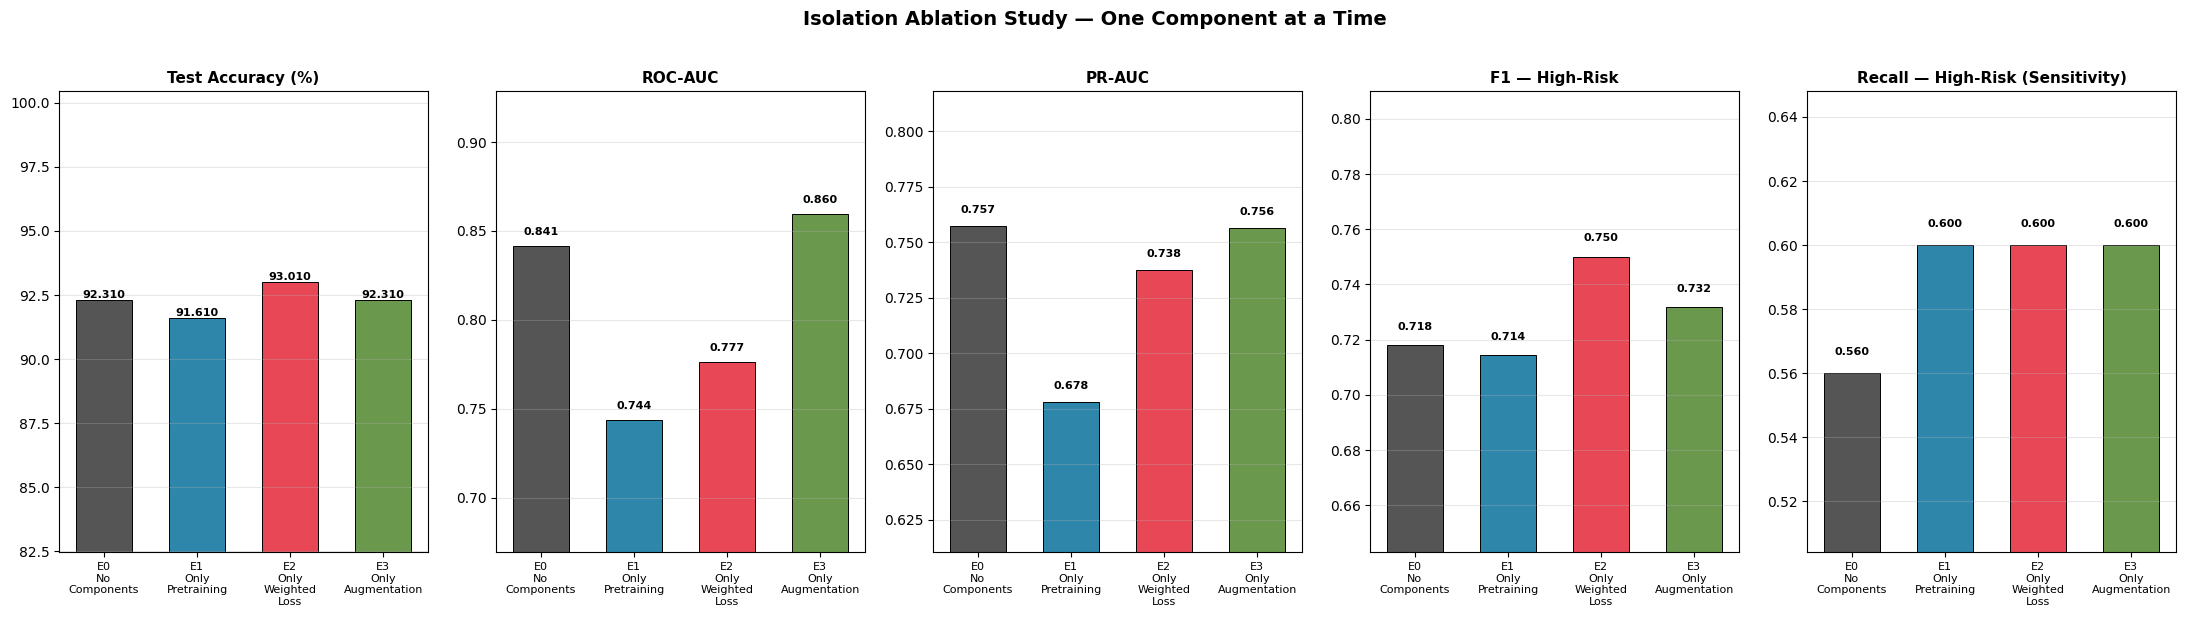

✅ Bar chart saved to: /content/drive/MyDrive/FINAL_YEAR/AblationClassificationResults/binary_results_efficientnet/isolation_ablation_results/isolation_ablation_bar_chart.png


In [ ]:
# ── Bar chart: metric comparison across experiments ───────────────────────────
plot_metrics = {
    'test_acc':          'Test Accuracy (%)',
    'roc_auc':           'ROC-AUC',
    'pr_auc':            'PR-AUC',
    'f1_high_risk':      'F1 — High-Risk',
    'recall_high_risk':  'Recall — High-Risk (Sensitivity)',
}

exp_labels = results_df['experiment'].tolist()
x = np.arange(len(exp_labels))
colors = ['#555555', '#2E86AB', '#E84855', '#6A994E']

fig, axes = plt.subplots(1, len(plot_metrics), figsize=(22, 6))

for ax, (col, title) in zip(axes, plot_metrics.items()):
    values = results_df[col].tolist()
    bars = ax.bar(x, values, color=colors, edgecolor='black', linewidth=0.7, width=0.6)
    ax.set_xticks(x)
    ax.set_xticklabels([e.replace('_', '\n') for e in exp_labels], fontsize=8)
    ax.set_title(title, fontweight='bold', fontsize=11)
    ax.set_ylim(min(values) * 0.9 if min(values) > 0 else 0, max(values) * 1.08)
    ax.grid(axis='y', alpha=0.3)
    for bar, val in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.005,
                f'{val:.3f}', ha='center', va='bottom', fontsize=8, fontweight='bold')

plt.suptitle('Isolation Ablation Study — One Component at a Time',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
chart_path = os.path.join(ABLATION_OUTPUT_DIR, 'isolation_ablation_bar_chart.png')
plt.savefig(chart_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"✅ Bar chart saved to: {chart_path}")


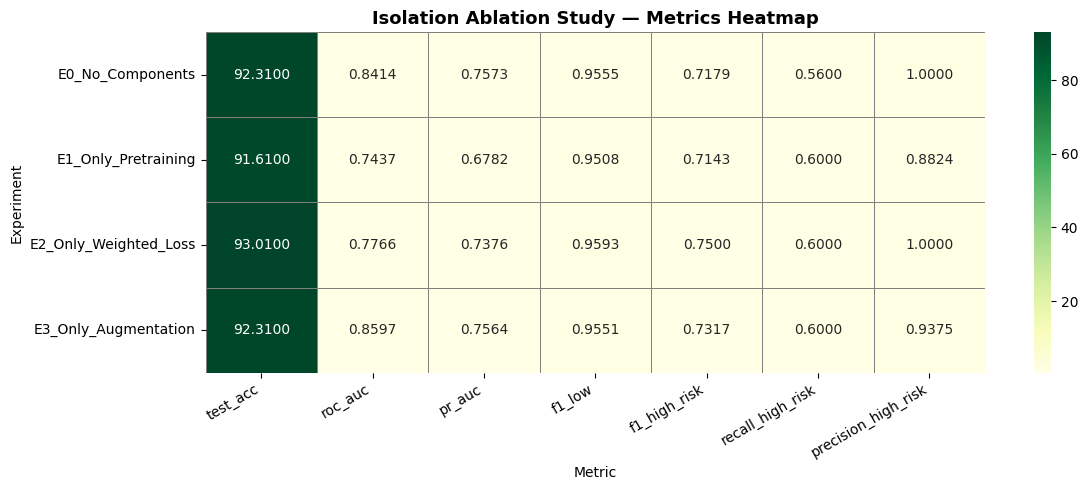

✅ Heatmap saved to: /content/drive/MyDrive/FINAL_YEAR/AblationClassificationResults/binary_results_efficientnet/isolation_ablation_results/isolation_ablation_heatmap.png

📁 All isolation ablation outputs saved under: /content/drive/MyDrive/FINAL_YEAR/AblationClassificationResults/binary_results_efficientnet/isolation_ablation_results


In [ ]:
# ── Heatmap: all metrics across all experiments ───────────────────────────────
heatmap_cols = ['test_acc', 'roc_auc', 'pr_auc', 'f1_low', 'f1_high_risk', 'recall_high_risk', 'precision_high_risk']
heatmap_data = results_df.set_index('experiment')[heatmap_cols]

plt.figure(figsize=(12, 5))
sns.heatmap(
    heatmap_data,
    annot=True, fmt='.4f', cmap='YlGn',
    linewidths=0.5, linecolor='grey',
    annot_kws={'size': 10}
)
plt.title('Isolation Ablation Study — Metrics Heatmap', fontweight='bold', fontsize=13)
plt.xlabel('Metric'); plt.ylabel('Experiment')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
heatmap_path = os.path.join(ABLATION_OUTPUT_DIR, 'isolation_ablation_heatmap.png')
plt.savefig(heatmap_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"✅ Heatmap saved to: {heatmap_path}")
print(f"\n📁 All isolation ablation outputs saved under: {ABLATION_OUTPUT_DIR}")
